# Taller 2 · Reformulación de un modelo entero mixto
## Distribución de oxígeno medicinal en un hospital: vínculo agregado frente a vínculo desagregado

**Investigación de Operaciones** · Doctorado en Ingeniería, consorcio UV–UTA

Cuaderno de resultados del taller. Ejecutado de principio a fin (*Entorno de ejecución → Ejecutar todas*) reproduce todas las tablas y figuras del informe, sin intervención manual y en pocos minutos. El planteamiento del caso, el modelo, la demostración de equivalencia y la discusión están en el `README.md` del repositorio.

| Sección | Contenido |
|---|---|
| 1 | Instalación y declaración de entorno |
| 2 | Configuración (única celda editable) |
| 3 | Instancias: escenario real y escenario ampliado |
| 4 | Modelo: una función, cuatro formulaciones |
| 5 | Brecha de la relajación y branch and bound explícito (I1 e I2), con validación contra el ejemplo de clase |
| 6 | Resolución con HiGHS y medición de indicadores |
| 7 | Verificación numérica de la equivalencia |
| 8 | Experimento |
| 9 | Resultados y verificación cruzada |
| 10 | Exportación |

## 1. Instalación y declaración de entorno

In [1]:
# Versiones con las que se obtuvieron los resultados del informe.
%pip install -q pyomo==6.10.1 highspy==1.15.1

In [2]:
import gc
import itertools
import json
import math
import os
import platform
import random
import re
import sys
import time
from importlib import metadata

import matplotlib.pyplot as plt
import pandas as pd
import pyomo.environ as pyo
import highspy


def version_de(paquete):
    """Versión instalada de un paquete, o 'no instalado'."""
    try:
        return metadata.version(paquete)
    except metadata.PackageNotFoundError:
        return "no instalado"


def leer_proc(ruta, clave):
    """Lee un campo de /proc (Linux). Devuelve 'no disponible' en otros sistemas."""
    try:
        with open(ruta) as f:
            for linea in f:
                if linea.startswith(clave):
                    return linea.split(":", 1)[1].strip()
    except OSError:
        pass
    return "no disponible"


def declarar_entorno(carpeta):
    """Registra equipo, sistema y versiones. Escribe entorno.json y requirements.txt."""
    try:
        version_highs = highspy.Highs().version()
    except Exception:
        version_highs = version_de("highspy")
    entorno = {
        "fecha_ejecucion": time.strftime("%Y-%m-%d %H:%M:%S"),
        "en_colab": "google.colab" in sys.modules,
        "sistema_operativo": platform.platform(),
        "procesador": leer_proc("/proc/cpuinfo", "model name"),
        "nucleos_logicos": os.cpu_count(),
        "memoria_total": leer_proc("/proc/meminfo", "MemTotal"),
        "python": platform.python_version(),
        "pyomo": version_de("pyomo"),
        "highspy": version_de("highspy"),
        "highs_solver": version_highs,
        "numpy": version_de("numpy"),
        "scipy": version_de("scipy"),
        "pandas": version_de("pandas"),
        "matplotlib": version_de("matplotlib"),
    }
    os.makedirs(carpeta, exist_ok=True)
    with open(os.path.join(carpeta, "entorno.json"), "w", encoding="utf-8") as f:
        json.dump(entorno, f, indent=2, ensure_ascii=False)
    with open(os.path.join(carpeta, "requirements.txt"), "w") as f:
        for p in ["pyomo", "highspy", "numpy", "scipy", "pandas", "matplotlib"]:
            f.write(f"{p}=={version_de(p)}\n")
    return entorno

## 2. Configuración

Todo lo que se puede ajustar está en esta celda; los valores por defecto reproducen el informe.

- `ESCENARIO = "ampliado"` es el caso principal. `"real"` reproduce el caso base con los datos del hospital, cuya brecha de relajación es nula.
- El límite de tiempo es la única opción del solver que se fija, porque lo exige el enunciado, y es igual para todas las formulaciones.
- `TOL_EQUIV = 1e-4` es la brecha relativa con la que HiGHS declara óptima una solución (`mip_rel_gap` por defecto): dos formulaciones equivalentes pueden diferir hasta en esa proporción.
- Cada escenario escribe sus resultados en su propia carpeta, `taller2_<escenario>/`.

In [3]:
# ---- escenario y datos ----
ESCENARIO = "ampliado"         # "ampliado": caso principal · "real": datos del hospital sin ramales ni cobertura
REPOSICIONES_ESTANQUE = None   # None = reposiciones ilimitadas · n = máximo de llenados por estanque en 4 semanas
K_RESPALDO = 1                 # mínimo de estanques habilitados (además de la reserva de cilindros)
SEMILLA = 2026                 # reparto de la demanda entre especialidades (I2 e I3)
USAR_DATOS_EXISTENTES = True   # reutiliza datos/<inst>.json si corresponde a estos mismos parámetros

# ---- experimento con HiGHS ----
INSTANCIAS = ["I1", "I2", "I3", "I4"]
FORMULACIONES = ["A", "B", "A0", "AB"]
LIMITE_TIEMPO = 300            # segundos por resolución entera
REPETICIONES = 3               # el enunciado exige al menos tres
TOL_EQUIV = 1e-4               # tolerancia relativa para comparar óptimos enteros

# ---- branch and bound explícito (sección 5) ----
INSTANCIAS_BB = ["I1", "I2"]
FORMULACIONES_BB = ["A", "B", "A0", "AB"]
ESTRATEGIA_BB = "mejor_cota"   # "mejor_cota" o "profundidad"
CASOS_BB = {                   # clave: (etiqueta, escenario, llenados por estanque)
    "ampliado": ("Ampliado · ramales y cobertura doble", "ampliado", None),
    "base":     ("Real · datos del hospital", "real", None),
}
CASOS_ARBOL = ["ampliado"]     # casos cuyo registro de nodos y árboles se muestran

assert ESCENARIO in ("real", "ampliado"), "ESCENARIO debe ser 'real' o 'ampliado'"
CARPETA = f"taller2_{ESCENARIO}"
if REPOSICIONES_ESTANQUE is not None:
    CARPETA += f"_llenados{REPOSICIONES_ESTANQUE}"
DIR = {n: os.path.join(CARPETA, n) for n in ["datos", "lp", "registros", "resultados", "figuras"]}
for d in DIR.values():
    os.makedirs(d, exist_ok=True)

entorno = declarar_entorno(DIR["resultados"])
pd.Series(entorno, name="valor").to_frame()

,valor
fecha_ejecucion,2026-10-09 20:10:08
en_colab,True
sistema_operativo,Linux-6.6.122+-x86_64-with-glibc2.39
procesador,Intel(R) Xeon(R) CPU @ 2.20GHz
nucleos_logicos,2
memoria_total,13286944 kB
python,3.13.16
pyomo,6.10.1
highspy,1.15.1
highs_solver,1.15.1


## 3. Instancias

### 3.1 Escenario real

Datos del hospital para un horizonte de 4 semanas, que se toma como equivalente a un mes.

| Dato | Valor |
|---|---|
| Demanda | Hospitalización 11.165,82 $m^3$ (543 camas); UPC 43.273,44 $m^3$ (159 camas); Pabellón 960 $m^3$ (19 pabellones). Total D = 55.399,26 $m^3$ |
| Precio por $m^3$ | Indura 435; Air Liquide 588; AGA/Linde 949 más 214 de transporte |
| Estanques | T1 (Air Liquide) y T2 (Indura), 26.100 $m^3$ de gas por llenado, reposiciones ilimitadas |
| Mantención de tomas | \$28.800 por toma al año, solo en suministro por red. En este escenario cada estanque habilitado paga las 740 tomas, \\$1.639.385 en 4 semanas |
| Bancos de cilindros | 20 cilindros de 0,6 $m^3$ con 4 recambios por horizonte (48 $m^3$); arriendo de \$12.000 por cilindro al mes |
| Reserva obligatoria | 100 cilindros, \$1.200.000; no se usan para la demanda normal y se suman fuera del modelo (`z_total`) |

Los valores sin dato del hospital están marcados como `SUPUESTO` en el código: el proveedor de cada estanque, los 4 recambios de cilindros, el número de bancos de I2 a I4 y el reparto de la demanda entre especialidades.

| Instancia | Fuentes | Puntos de suministro | \|C\| |
|---|---|---|---|
| I1 | 2 estanques + 1 banco | Servicio general | 3 |
| I2 | 2 estanques + 4 bancos | 3 especialidades por servicio | 9 |
| I3 | 2 estanques + 10 bancos | Pabellón por pabellón (19); UPC y Hospitalización por especialidad (6 + 6) | 31 |
| I4 | 2 estanques + 42 bancos | Pabellón por pabellón (19); UPC por cama (159); Hospitalización por habitación de 3 camas (181) | 359 |

In [4]:
# ---------------- datos del escenario real ----------------
HORIZONTE_SEMANAS = 4
CAMAS = {"HOSP": 543, "UPC": 159}
PABELLONES = 19
CONSUMO_CAMA = {"HOSP": (0.85, 0.20, 3.0),    # (ocupación, fracción con O₂, L/min por paciente)
                "UPC":  (0.90, 0.75, 10.0)}
DEMANDA_PAB_SEMANAL = 240.0                    # m³/semana, los 19 pabellones
CAMAS_POR_HABITACION = 3
N_HABITACIONES = CAMAS["HOSP"] // CAMAS_POR_HABITACION
TOMAS = {"UPC": CAMAS["UPC"],                          # 1 por cama
         "HOSP": N_HABITACIONES * 3,                   # 3 tomas por habitación de 3 camas
         "PAB": PABELLONES * 2}                        # 2 por pabellón

PROVEEDORES_REAL = {   # $/m³
    "Indura":     {"precio": 435.0, "transporte": 0.0},
    "AirLiquide": {"precio": 588.0, "transporte": 0.0},
    "AGA/Linde":  {"precio": 949.0, "transporte": 214.0},
}
MANTENCION_TOMA_ANUAL = 28800.0          # $ por toma al año (solo suministro por red)
ARRIENDO_CILINDRO = 12000.0              # $ por cilindro al mes
CILINDROS_RESERVA = 100                  # reserva obligatoria, no usable para demanda normal
M3_POR_CILINDRO = 0.6                    # m³ de gas por cilindro (600 L)
CILINDROS_POR_BANCO = 20
RECAMBIOS_HORIZONTE = 4                  # SUPUESTO: un recambio por semana
CAPACIDAD_ESTANQUE = 26100.0             # m³ de gas por llenado (estanque LOX de 30 m³)
ESTANQUES_REAL = [("T1", "AirLiquide"), ("T2", "Indura")]   # SUPUESTO: proveedor de cada estanque

# SUPUESTO: bancos de I4 según la versión 2 del documento. Las instancias menores toman los primeros.
TIPOS_BANCO = ["manifold_pabellon"] * 19 + ["estacion_enfermeria"] * 14 + ["emergencia"] * 9
ESTRUCTURA_REAL = {
    "I1": {"n_bancos": 1,  "puntos": {"PAB": ("general", 1), "UPC": ("general", 1), "HOSP": ("general", 1)}},
    "I2": {"n_bancos": 4,  "puntos": {"PAB": ("esp", 3), "UPC": ("esp", 3), "HOSP": ("esp", 3)}},
    "I3": {"n_bancos": 10, "puntos": {"PAB": ("pabellon", PABELLONES), "UPC": ("esp", 6), "HOSP": ("esp", 6)}},
    "I4": {"n_bancos": 42, "puntos": {"PAB": ("pabellon", PABELLONES), "UPC": ("cama", CAMAS["UPC"]),
                                       "HOSP": ("habitacion", N_HABITACIONES)}},
}


def demanda_horizonte():
    """Demanda de cada servicio en el horizonte, calculada desde los supuestos de consumo."""
    d = {}
    for serv, (ocupacion, fraccion, lmin) in CONSUMO_CAMA.items():
        caudal = CAMAS[serv] * ocupacion * fraccion * lmin          # L/min promedio
        d[serv] = caudal * 60 * 24 * 7 / 1000 * HORIZONTE_SEMANAS   # m³
    d["PAB"] = DEMANDA_PAB_SEMANAL * HORIZONTE_SEMANAS
    return d


def generar_real(nombre, semilla=SEMILLA, k=K_RESPALDO):
    """Instancia con los datos del hospital. Solo el reparto por especialidad es aleatorio."""
    e = ESTRUCTURA_REAL[nombre]
    dem = demanda_horizonte()
    D = sum(dem.values())
    mantencion = MANTENCION_TOMA_ANUAL * sum(TOMAS.values()) * HORIZONTE_SEMANAS / 52

    fuentes = []
    for id_estanque, prov in ESTANQUES_REAL:
        # reposiciones ilimitadas: la capacidad iguala la demanda total, que no restringe nada
        U = D if REPOSICIONES_ESTANQUE is None else REPOSICIONES_ESTANQUE * CAPACIDAD_ESTANQUE
        fuentes.append({"id": id_estanque, "tipo": "estanque", "proveedor": prov,
                        "U": U, "F": round(mantencion, 2), "cuenta_respaldo": True})
    for j in range(e["n_bancos"]):
        fuentes.append({"id": f"B{j+1:02d}", "tipo": "cilindro", "proveedor": "AGA/Linde",
                        "ubicacion": TIPOS_BANCO[j],
                        "U": CILINDROS_POR_BANCO * M3_POR_CILINDRO * RECAMBIOS_HORIZONTE,
                        "F": CILINDROS_POR_BANCO * ARRIENDO_CILINDRO,
                        "cuenta_respaldo": False})

    rnd = random.Random(f"{semilla}-{nombre}")
    puntos = []
    for serv, (nivel, n) in e["puntos"].items():
        if nivel == "esp":      # SUPUESTO: especialidades de distinto tamaño, pesos con semilla
            pesos = [rnd.uniform(0.5, 1.5) for _ in range(n)]
        else:                   # pabellones, camas o habitaciones idénticos: reparto parejo
            pesos = [1.0] * n
        suma = sum(pesos)
        for i in range(n):
            puntos.append({"id": f"{serv}_{nivel}_{i+1:03d}", "servicio": serv,
                           "d": round(dem[serv] * pesos[i] / suma, 4)})

    c = {}
    for f in fuentes:
        prov = PROVEEDORES_REAL[f["proveedor"]]
        c[f["id"]] = {p["id"]: prov["precio"] + prov["transporte"] for p in puntos}
    return {"nombre": nombre, "escenario": "real", "semilla": semilla, "k": k,
            "costo_constante": CILINDROS_RESERVA * ARRIENDO_CILINDRO,   # reserva obligatoria
            "fuentes": fuentes, "puntos": puntos, "c": c}

### 3.2 Escenario ampliado: ramales por sector y cobertura doble

Agrega al escenario real cuatro rasgos posibles en un hospital. Son supuestos plausibles, no datos del hospital, y todo lo demás no cambia.

- **Ramales por sector.** T1 (Air Liquide) llega a Pabellón y UPC; T2 (Indura) llega a UPC y Hospitalización. Pabellón solo puede recibir de T1 o de cilindros.
- **Mantención por ramal.** T1 paga las 197 tomas de su ramal (\$436.431 en 4 semanas) y T2 las 702 del suyo (\$1.555.200). Si ambos se habilitan, las tomas de UPC se pagan a los dos proveedores.
- **Cilindros de alcance flexible.** Los bancos pueden llevarse a cualquier punto.
- **Cobertura doble.** Cada punto de Pabellón y de UPC debe tener al menos dos fuentes habilitadas que puedan abastecerlo.

Queda fuera la suspensión del suministro de Indura por pagos atrasados, porque requiere modelar incertidumbre.

In [5]:
# ---------------- escenario ampliado: ramales por sector y cobertura doble ----------------
RAMALES = {"T1": ["PAB", "UPC"], "T2": ["UPC", "HOSP"]}   # SUPUESTO: servicios que alcanza cada estanque
ALCANCE_BANCOS = None                                      # None = alcance flexible (cualquier punto)
COBERTURA_DOBLE = {"PAB": 2, "UPC": 2}                     # SUPUESTO: fuentes habilitadas mínimas por punto


def generar_ampliado(nombre, semilla=SEMILLA, k=K_RESPALDO):
    """Escenario real + ramales por sector, mantención por ramal, cilindros flexibles y cobertura doble."""
    datos = generar_real(nombre, semilla=semilla, k=k)
    mantencion_por_toma = MANTENCION_TOMA_ANUAL * HORIZONTE_SEMANAS / 52
    for f in datos["fuentes"]:
        if f["tipo"] == "estanque":
            f["alcance"] = RAMALES[f["id"]]
            f["F"] = round(mantencion_por_toma * sum(TOMAS[s] for s in f["alcance"]), 2)
        else:
            f["alcance"] = ALCANCE_BANCOS
    datos["escenario"] = "ampliado"
    datos["cobertura"] = COBERTURA_DOBLE
    return datos

In [6]:
def puede_abastecer(fuente, punto):
    """True si la fuente alcanza el punto: sin restricción de alcance, o el servicio del punto está en él."""
    alcance = fuente.get("alcance")
    return alcance is None or punto.get("servicio") in alcance


def verificar_instancia(datos):
    """Comprueba los supuestos del documento. Detiene la ejecución si fallan."""
    D = sum(p["d"] for p in datos["puntos"])
    U = sum(f["U"] for f in datos["fuentes"])
    assert all(p["d"] > 0 for p in datos["puntos"]), "hay demandas no positivas"
    assert all(f["U"] > 0 and f["F"] >= 0 for f in datos["fuentes"]), "capacidad o costo fijo inválido"
    assert U >= D, (f"{datos['nombre']}: la capacidad total ({U:,.0f}) no cubre la demanda ({D:,.0f}); "
                    "con reposiciones limitadas, subir REPOSICIONES_ESTANQUE")
    for p in datos["puntos"]:
        n_alcanzan = sum(puede_abastecer(f, p) for f in datos["fuentes"])
        minimo = max(1, (datos.get("cobertura") or {}).get(p.get("servicio"), 0))
        assert n_alcanzan >= minimo, (f"{datos['nombre']}: el punto {p['id']} necesita {minimo} fuentes "
                                      f"y solo {n_alcanzan} lo alcanzan")
    n_resp = sum(f.get("cuenta_respaldo", True) for f in datos["fuentes"])
    assert datos["k"] <= n_resp, f"{datos['nombre']}: k mayor que el número de fuentes de respaldo"


def huella_actual():
    """Resumen de los parámetros que determinan las instancias. Si cambia, se regeneran."""
    base = {"escenario": ESCENARIO, "semilla": SEMILLA, "k": K_RESPALDO}
    if ESCENARIO in ("real", "ampliado"):
        base.update({"reposiciones": REPOSICIONES_ESTANQUE, "horizonte": HORIZONTE_SEMANAS,
                     "camas": CAMAS, "pabellones": PABELLONES, "consumo": CONSUMO_CAMA,
                     "pab_semanal": DEMANDA_PAB_SEMANAL, "proveedores": PROVEEDORES_REAL,
                     "mantencion": MANTENCION_TOMA_ANUAL, "tomas": TOMAS, "arriendo": ARRIENDO_CILINDRO,
                     "reserva": CILINDROS_RESERVA, "m3_cilindro": M3_POR_CILINDRO,
                     "cil_banco": CILINDROS_POR_BANCO, "recambios": RECAMBIOS_HORIZONTE,
                     "cap_estanque": CAPACIDAD_ESTANQUE, "estanques": ESTANQUES_REAL})
    if ESCENARIO == "ampliado":
        base.update({"ramales": RAMALES, "alcance_bancos": ALCANCE_BANCOS, "cobertura": COBERTURA_DOBLE})
    return json.dumps(base, sort_keys=True)


def obtener_instancia(nombre):
    """Carga datos/<nombre>.json si existe y corresponde a los parámetros actuales; si no, la genera."""
    ruta = os.path.join(DIR["datos"], f"{nombre}.json")
    huella = huella_actual()
    datos, origen = None, "generada"
    if USAR_DATOS_EXISTENTES and os.path.exists(ruta):
        with open(ruta, encoding="utf-8") as f:
            guardada = json.load(f)
        if guardada.get("huella") == huella:
            datos, origen = guardada, "cargada"
    if datos is None:
        generador = {"real": generar_real, "ampliado": generar_ampliado}[ESCENARIO]
        datos = generador(nombre)
        datos["huella"] = huella
        with open(ruta, "w", encoding="utf-8") as f:
            json.dump(datos, f, ensure_ascii=False)
    datos["k"] = K_RESPALDO      # la configuración manda sobre el archivo
    verificar_instancia(datos)
    return datos, origen

In [7]:
DATOS = {}
filas = []
for nombre in INSTANCIAS:
    DATOS[nombre], origen = obtener_instancia(nombre)
    dat = DATOS[nombre]
    D = sum(p["d"] for p in dat["puntos"])
    filas.append({"instancia": nombre, "origen": origen,
                  "|S|": len(dat["fuentes"]), "|C|": len(dat["puntos"]),
                  "demanda total D": round(D, 1),
                  "capacidad total / D": round(sum(f["U"] for f in dat["fuentes"]) / D, 2),
                  "max U_s / D": round(max(f["U"] for f in dat["fuentes"]) / D, 2),
                  "costo constante $": dat.get("costo_constante", 0.0),
                  "vínculos A": len(dat["fuentes"]),
                  "vínculos B": sum(puede_abastecer(f, p) for f in dat["fuentes"] for p in dat["puntos"])})
resumen_instancias = pd.DataFrame(filas)
resumen_instancias.to_csv(os.path.join(DIR["resultados"], "resumen_instancias.csv"), index=False)
resumen_instancias

,instancia,origen,|S|,|C|,demanda total D,capacidad total / D,max U_s / D,costo constante $,vínculos A,vínculos B
0,I1,generada,3,3,55399.3,2.00,1.0,1200000.0,3,7
1,I2,generada,6,9,55399.3,2.00,1.0,1200000.0,6,48
2,I3,generada,12,31,55399.3,2.01,1.0,1200000.0,12,347
3,I4,generada,44,359,55399.3,2.04,1.0,1200000.0,44,15596


## 4. Modelo

Una sola función construye las cuatro formulaciones sobre los mismos datos: `formulacion` elige la restricción de vínculo y `relajado` decide si y es binaria o continua en [0, 1].

$$\min\; \sum_s F_s\, y_s + \sum_{(s,c)} c_{sc}\, x_{sc}$$

$$\sum_{s \in S(c)} x_{sc} = d_c \;\;\forall c, \qquad \sum_{c \in C(s)} x_{sc} \le U_s \;\;\forall s, \qquad \sum_{s \in R} y_s \ge k, \qquad \sum_{s \in S(c)} y_s \ge m_c \;\;\forall c \text{ crítico}$$

S(c) son las fuentes que alcanzan el punto c y C(s) los puntos que alcanza la fuente s (en el escenario real, todos). R es el conjunto de estanques. m_c es la cobertura mínima: 2 en Pabellón y UPC, solo en el escenario ampliado.

| Formulación | Restricción de vínculo | Filas |
|---|---|---|
| A, agregada | $\sum_c x_{sc} \le \min(U_s, D_s)\, y_s$, con $D_s$ la demanda que s alcanza | una por fuente |
| A0, agregada con M = D | $\sum_c x_{sc} \le D\, y_s$ | una por fuente |
| B, desagregada | $x_{sc} \le \min(d_c, U_s)\, y_s$ | una por arco fuente–punto |
| AB | A y B a la vez | ambas |

Con y entera las cuatro imponen lo mismo, de modo que comparten el conjunto de soluciones enteras (la demostración está en el README). Difieren solo en la relajación lineal.

In [8]:
def construir(datos, formulacion, relajado=False):
    """Construye el modelo de Pyomo para una formulación sobre los datos dados."""
    assert formulacion in ("A", "B", "A0", "AB"), f"formulación desconocida: {formulacion}"
    fuentes = {f["id"]: f for f in datos["fuentes"]}
    puntos = {p["id"]: p for p in datos["puntos"]}
    S, C = list(fuentes), list(puntos)
    U = {s: fuentes[s]["U"] for s in S}
    F = {s: fuentes[s]["F"] for s in S}
    d = {p: puntos[p]["d"] for p in C}
    c = datos["c"]
    D = sum(d.values())

    # arcos fuente-punto permitidos: todos, salvo que el escenario restrinja el alcance (ramales)
    arcos = [(s, p) for s in S for p in C if puede_abastecer(fuentes[s], puntos[p])]
    puntos_de = {s: [p for (t, p) in arcos if t == s] for s in S}
    fuentes_de = {p: [s for (s, q) in arcos if q == p] for p in C}
    D_alcanzable = {s: sum(d[p] for p in puntos_de[s]) for s in S}   # demanda que s puede atender

    m = pyo.ConcreteModel(name=f"{datos['nombre']}_{formulacion}")
    m.S = pyo.Set(initialize=S, ordered=True)
    m.C = pyo.Set(initialize=C, ordered=True)
    m.ARCOS = pyo.Set(initialize=arcos, dimen=2, ordered=True)

    m.y = pyo.Var(m.S, domain=pyo.UnitInterval if relajado else pyo.Binary)
    m.x = pyo.Var(m.ARCOS, domain=pyo.NonNegativeReals)

    m.costo = pyo.Objective(
        expr=pyo.quicksum(F[s] * m.y[s] for s in S)
        + pyo.quicksum(c[s][p] * m.x[s, p] for (s, p) in arcos),
        sense=pyo.minimize)

    # ---- restricciones comunes, idénticas en todas las formulaciones ----
    m.demanda = pyo.Constraint(m.C, rule=lambda m, p:
                               pyo.quicksum(m.x[s, p] for s in fuentes_de[p]) == d[p])
    m.capacidad = pyo.Constraint(m.S, rule=lambda m, s:
        (pyo.quicksum(m.x[s, p] for p in puntos_de[s]) <= U[s]) if puntos_de[s] else pyo.Constraint.Skip)
    fuentes_respaldo = [f["id"] for f in datos["fuentes"] if f.get("cuenta_respaldo", True)]
    m.respaldo = pyo.Constraint(expr=pyo.quicksum(m.y[s] for s in fuentes_respaldo) >= datos["k"])

    # cobertura: cada punto crítico necesita al menos m fuentes habilitadas que lo alcancen
    # (los puntos con el mismo conjunto de fuentes comparten una sola fila)
    cobertura = datos.get("cobertura") or {}
    grupos = sorted({(tuple(fuentes_de[p]), cobertura[puntos[p]["servicio"]])
                     for p in C if puntos[p].get("servicio") in cobertura})
    if grupos:
        m.GRUPOS = pyo.Set(initialize=list(range(len(grupos))), ordered=True)
        m.cobertura = pyo.Constraint(m.GRUPOS, rule=lambda m, g:
                                     pyo.quicksum(m.y[s] for s in grupos[g][0]) >= grupos[g][1])

    # ---- restricción de vínculo: lo único que cambia entre formulaciones ----
    if formulacion in ("A", "AB"):
        # agregada, con la menor constante válida derivable de los datos: min(U_s, D_s)
        m.vinculo_agregado = pyo.Constraint(m.S, rule=lambda m, s:
            (pyo.quicksum(m.x[s, p] for p in puntos_de[s]) <= min(U[s], D_alcanzable[s]) * m.y[s])
            if puntos_de[s] else pyo.Constraint.Skip)
    if formulacion == "A0":
        # agregada, con la constante genérica M = D (variante de la versión 2)
        m.vinculo_agregado = pyo.Constraint(m.S, rule=lambda m, s:
            (pyo.quicksum(m.x[s, p] for p in puntos_de[s]) <= D * m.y[s])
            if puntos_de[s] else pyo.Constraint.Skip)
    if formulacion in ("B", "AB"):
        # desagregada: una restricción por arco fuente-punto
        m.vinculo_desagregado = pyo.Constraint(m.ARCOS, rule=lambda m, s, p:
            m.x[s, p] <= min(d[p], U[s]) * m.y[s])
    return m

## 5. Brecha de la relajación y branch and bound explícito (I1 e I2)

HiGHS resuelve todas las instancias en la raíz, porque aplica presolve, heurísticas y cortes. Para ver cuánto trabajo deja cada formulación al árbol, esta sección resuelve I1 e I2 con un branch and bound escrito a mano, sin esas ayudas. En cada nodo se resuelve la relajación lineal, se ramifica sobre la y_s más fraccionaria, se elige el nodo de mejor cota y se poda por infactibilidad, integralidad o cota. La cota de la raíz es la relajación lineal pura. Es un instrumento complementario: el indicador de nodos del enunciado es el de HiGHS (sección 8).

El LP de cada nodo se escribe en forma matricial con `scipy`. Que represente el mismo modelo que Pyomo se comprueba tres veces: reproduce el ejemplo de clase (5.1), las cuatro formulaciones llegan al mismo óptimo (5.2) y coincide con HiGHS en cota raíz y óptimo (9.1).

In [9]:
import numpy as np
from scipy.optimize import linprog
from scipy.sparse import lil_matrix
from matplotlib.patches import Patch

try:
    from IPython.display import display
except ImportError:      # fuera de Jupyter
    display = print

TOL_ENTERO = 1e-6        # una y se considera entera si dista menos de esto de 0 o 1
TOL_BB = 1e-7            # tolerancia relativa para podar por cota


def armar_lp(datos, formulacion):
    """Relajación lineal en forma matricial: el mismo modelo que construir(), para scipy.

    Variables: primero las x[s, c] (fila s, columna c) y después las y[s]. Los arcos que una
    fuente no alcanza quedan con cota superior 0.
    """
    assert formulacion in ("A", "B", "A0", "AB"), f"formulación desconocida: {formulacion}"
    S = [f["id"] for f in datos["fuentes"]]
    P = datos["puntos"]
    C = [p["id"] for p in P]
    U = [f["U"] for f in datos["fuentes"]]
    F = [f["F"] for f in datos["fuentes"]]
    respaldo = [i for i, f in enumerate(datos["fuentes"]) if f.get("cuenta_respaldo", True)]
    d = [p["d"] for p in P]
    D = sum(d)
    nS, nC = len(S), len(C)
    nx = nS * nC
    ix = lambda i, j: i * nC + j          # posición de x[s_i, c_j]
    iy = lambda i: nx + i                 # posición de y[s_i]
    alcanza = [[puede_abastecer(f, p) for p in P] for f in datos["fuentes"]]
    D_alc = [sum(d[j] for j in range(nC) if alcanza[i][j]) for i in range(nS)]

    c = np.zeros(nx + nS)
    for i in range(nS):
        c[iy(i)] = F[i]
        for j in range(nC):
            if alcanza[i][j]:
                c[ix(i, j)] = datos["c"][S[i]][C[j]]

    A_eq = lil_matrix((nC, nx + nS))      # demanda: cada punto recibe exactamente d_c
    for j in range(nC):
        for i in range(nS):
            if alcanza[i][j]:
                A_eq[j, ix(i, j)] = 1.0

    filas, b = [], []                     # desigualdades "fila · variables <= b"
    for i in range(nS):                   # capacidad de cada fuente
        filas.append({ix(i, j): 1.0 for j in range(nC) if alcanza[i][j]}); b.append(U[i])
    if respaldo and datos["k"] > 0:       # respaldo: sum y >= k
        filas.append({iy(i): -1.0 for i in respaldo}); b.append(-datos["k"])
    cobertura = datos.get("cobertura") or {}
    grupos = sorted({(tuple(i for i in range(nS) if alcanza[i][j]), cobertura[P[j]["servicio"]])
                     for j in range(nC) if P[j].get("servicio") in cobertura})
    for conjunto, minimo in grupos:       # cobertura: sum y >= m_c en cada punto crítico
        filas.append({iy(i): -1.0 for i in conjunto}); b.append(-minimo)
    if formulacion in ("A", "AB"):        # vínculo agregado con M_s = min(U_s, D_s)
        for i in range(nS):
            fila = {ix(i, j): 1.0 for j in range(nC) if alcanza[i][j]}
            fila[iy(i)] = -min(U[i], D_alc[i])
            filas.append(fila); b.append(0.0)
    if formulacion == "A0":               # vínculo agregado con M = D
        for i in range(nS):
            fila = {ix(i, j): 1.0 for j in range(nC) if alcanza[i][j]}
            fila[iy(i)] = -D
            filas.append(fila); b.append(0.0)
    if formulacion in ("B", "AB"):        # vínculo desagregado con m_sc = min(d_c, U_s)
        for i in range(nS):
            for j in range(nC):
                if alcanza[i][j]:
                    filas.append({ix(i, j): 1.0, iy(i): -min(d[j], U[i])}); b.append(0.0)

    A_ub = lil_matrix((len(filas), nx + nS))
    for r, fila in enumerate(filas):
        for col, valor in fila.items():
            A_ub[r, col] = valor
    ub_x = [None if alcanza[i][j] else 0.0 for i in range(nS) for j in range(nC)]
    return {"c": c, "A_ub": A_ub.tocsr(), "b_ub": np.array(b), "A_eq": A_eq.tocsr(),
            "b_eq": np.array(d), "nx": nx, "nS": nS, "S": S, "ub_x": ub_x}


def resolver_nodo(lp, lb, ub):
    """LP de un nodo: y acotadas por [lb, ub]. Devuelve (valor, y) o (None, None) si es infactible."""
    cotas = [(0, u) for u in lp["ub_x"]] + list(zip(lb, ub))
    r = linprog(lp["c"], A_ub=lp["A_ub"], b_ub=lp["b_ub"], A_eq=lp["A_eq"], b_eq=lp["b_eq"],
                bounds=cotas, method="highs")
    if r.status == 2:
        return None, None
    assert r.status == 0, f"el LP del nodo no se resolvió: {r.message}"
    return float(r.fun), r.x[lp["nx"]:]


def branch_and_bound(datos, formulacion, estrategia="mejor_cota", max_nodos=5000):
    """Branch and bound explícito sobre las variables de habilitación y."""
    lp = armar_lp(datos, formulacion)
    nS, S = lp["nS"], lp["S"]
    nodos, abiertos, incumbentes = [], [], []
    inc = {"z": math.inf, "y": None}      # mejor solución entera conocida

    def no_mejora(z):                     # ¿una cota z ya no puede mejorar la incumbente?
        return math.isfinite(inc["z"]) and z >= inc["z"] - TOL_BB * max(1.0, abs(inc["z"]))

    def crear(padre, prof, lb, ub, decision):
        """Crea un nodo, resuelve su LP y lo clasifica."""
        z, y = resolver_nodo(lp, lb, ub)
        n = {"id": len(nodos), "padre": padre, "prof": prof, "decision": decision,
             "lb": lb, "ub": ub, "z": z, "y": y, "estado": None, "ramifica_en": None}
        nodos.append(n)
        if z is None:
            n["estado"] = "infactible"
        elif no_mejora(z):
            n["estado"] = "podado por cota"
        elif max(abs(v - round(v)) for v in y) <= TOL_ENTERO:
            n["estado"] = "entero"        # solución factible: nueva incumbente
            inc["z"], inc["y"] = z, [int(round(v)) for v in y]
            incumbentes.append(n["id"])
        else:
            n["estado"] = "abierto"       # fraccionario y prometedor: queda por ramificar
            abiertos.append(n)
        return n

    crear(None, 0, [0.0] * nS, [1.0] * nS, "raíz")
    while abiertos:
        assert len(nodos) < max_nodos, "se alcanzó el máximo de nodos"
        n = (min(abiertos, key=lambda a: (a["z"], a["id"])) if estrategia == "mejor_cota"
             else abiertos[-1])
        abiertos.remove(n)
        if no_mejora(n["z"]):             # la incumbente mejoró desde que se creó el nodo
            n["estado"] = "podado por cota"
            continue
        j = max(range(nS), key=lambda i: 0.5 - abs(n["y"][i] - 0.5))   # la más fraccionaria
        n["estado"], n["ramifica_en"] = "ramificado", S[j]
        for valor in (0, 1):
            lb, ub = list(n["lb"]), list(n["ub"])
            if valor == 0:
                ub[j] = 0.0
            else:
                lb[j] = 1.0
            crear(n["id"], n["prof"] + 1, lb, ub, f"y[{S[j]}] = {valor}")

    for k, id_nodo in enumerate(incumbentes):    # la última incumbente es el óptimo
        nodos[id_nodo]["estado"] = ("entero (óptimo)" if k == len(incumbentes) - 1
                                    else "entero (incumbente superada)")
    return {"nodos": nodos, "optimo": inc["z"], "y": inc["y"], "S": S,
            "cota_raiz": nodos[0]["z"], "n_nodos": len(nodos)}


def resumen_arbol(r):
    """Métricas de un árbol: cómo terminó cada nodo y cuánto mide la brecha de la raíz."""
    estados = pd.Series([n["estado"] for n in r["nodos"]])
    return {"cota_raiz": r["cota_raiz"], "optimo": r["optimo"],
            "brecha_relaj_%": 100 * (r["optimo"] - r["cota_raiz"]) / r["optimo"],
            "nodos": r["n_nodos"], "prof_max": max(n["prof"] for n in r["nodos"]),
            "ramificados": int((estados == "ramificado").sum()),
            "infactibles": int((estados == "infactible").sum()),
            "podados_por_cota": int((estados == "podado por cota").sum()),
            "enteros": int(estados.str.startswith("entero").sum())}

In [10]:
# ---------------- presentación: registro de nodos y dibujo de árboles ----------------
COLORES_ESTADO = {"ramificado": "#cfe2f3", "entero (óptimo)": "#93c47d",
                  "entero (incumbente superada)": "#d9ead3",
                  "podado por cota": "#fce5cd", "infactible": "#f4cccc"}


def formato_valor(z):
    """Valor de costo legible: millones si es grande."""
    return "—" if z is None else (f"{z / 1e6:,.3f} M" if abs(z) >= 1e6 else f"{z:,.1f}")


def registro_nodos(r):
    """Tabla de nodos de un árbol de branch and bound."""
    filas = []
    for n in r["nodos"]:
        fracc = ([] if n["y"] is None else
                 [f"{r['S'][i]}={v:.3f}" for i, v in enumerate(n["y"]) if TOL_ENTERO < v < 1 - TOL_ENTERO])
        filas.append({"nodo": n["id"], "padre": "—" if n["padre"] is None else n["padre"],
                      "prof": n["prof"], "decisión": n["decision"], "cota LP": formato_valor(n["z"]),
                      "y fraccionarias": ", ".join(fracc) or "—", "estado": n["estado"],
                      "ramifica en": n["ramifica_en"] or "—"})
    return pd.DataFrame(filas)


def dibujar_arbol(r, ax, titulo):
    """Dibuja un árbol de B&B: hojas equiespaciadas y cada padre centrado sobre sus hijos."""
    nodos = {n["id"]: n for n in r["nodos"]}
    hijos = {i: [] for i in nodos}
    for n in r["nodos"]:
        if n["padre"] is not None:
            hijos[n["padre"]].append(n["id"])

    pos, contador = {}, [0]
    def colocar(i):
        if hijos[i]:
            for h in hijos[i]:
                colocar(h)
            x = sum(pos[h][0] for h in hijos[i]) / len(hijos[i])
        else:
            x = contador[0]
            contador[0] += 1
        pos[i] = (x, -nodos[i]["prof"])
    colocar(0)

    for i, n in nodos.items():                       # aristas con su decisión
        if n["padre"] is not None:
            (x0, y0), (x1, y1) = pos[n["padre"]], pos[i]
            ax.plot([x0, x1], [y0, y1], color="0.55", lw=1, zorder=1)
            ax.text((x0 + x1) / 2, (y0 + y1) / 2, n["decision"], fontsize=7, ha="center",
                    va="center", zorder=2, bbox=dict(fc="white", ec="none", pad=0.6))
    for i, n in nodos.items():                       # nodos
        texto = f"#{i}\n" + ("infactible" if n["z"] is None else formato_valor(n["z"]))
        if n["ramifica_en"]:
            texto += f"\nramifica: {n['ramifica_en']}"
        ax.text(*pos[i], texto, ha="center", va="center", fontsize=7.5, zorder=3,
                bbox=dict(boxstyle="round,pad=0.35", fc=COLORES_ESTADO[n["estado"]], ec="0.3", lw=0.8))

    prof = max(n["prof"] for n in r["nodos"])
    ax.set_xlim(-0.8, max(contador[0] - 1, 0) + 0.8)
    ax.set_ylim(-prof - 0.7, 0.7)
    ax.set_title(titulo, fontsize=10)
    ax.axis("off")


def figura_arboles(lista, titulo, ruta, ncols=2):
    """Dibuja varios árboles en una figura. lista = [(subtítulo, resultado_bb), ...]."""
    nfilas = math.ceil(len(lista) / ncols)
    fig, ejes = plt.subplots(nfilas, ncols, figsize=(11, 3.5 * nfilas), squeeze=False)
    for ax, (sub, r) in zip(ejes.flat, lista):
        dibujar_arbol(r, ax, f"{sub} · {r['n_nodos']} " + ("nodo" if r["n_nodos"] == 1 else "nodos"))
    for ax in list(ejes.flat)[len(lista):]:
        ax.axis("off")
    fig.suptitle(titulo, fontsize=12)
    fig.legend(handles=[Patch(fc=c, ec="0.3", label=e) for e, c in COLORES_ESTADO.items()],
               loc="lower center", ncol=len(COLORES_ESTADO), fontsize=8, frameon=False)
    fig.tight_layout(rect=(0, 0.05, 1, 0.96))
    fig.savefig(ruta, dpi=200)
    plt.show()

### 5.1 Validación con el ejemplo de clase

El cuaderno `02_Formulaciones` del curso (4 sitios, 8 faenas, sin capacidades) tiene resultado conocido: la relajación agregada da 2.098,61 (brecha de 27,26 %) y la desagregada da 2.885,00, igual al óptimo entero. La celda se detiene si el código no reproduce esas cifras.

Validación correcta: el código reproduce 2.098,61 (agregada), 2.885,00 (desagregada) y el óptimo 2.885,00.


,formulacion,cota_raiz,optimo,brecha_relaj_%,nodos,prof_max,ramificados,infactibles,podados_por_cota,enteros
0,A,2098.610000,2885.000000,27.260000,17,4,8,0,7,2
1,B,2885.000000,2885.000000,0.000000,1,0,0,0,0,1
2,A0,2098.610000,2885.000000,27.260000,17,4,8,0,7,2
3,AB,2885.000000,2885.000000,0.000000,1,0,0,0,0,1


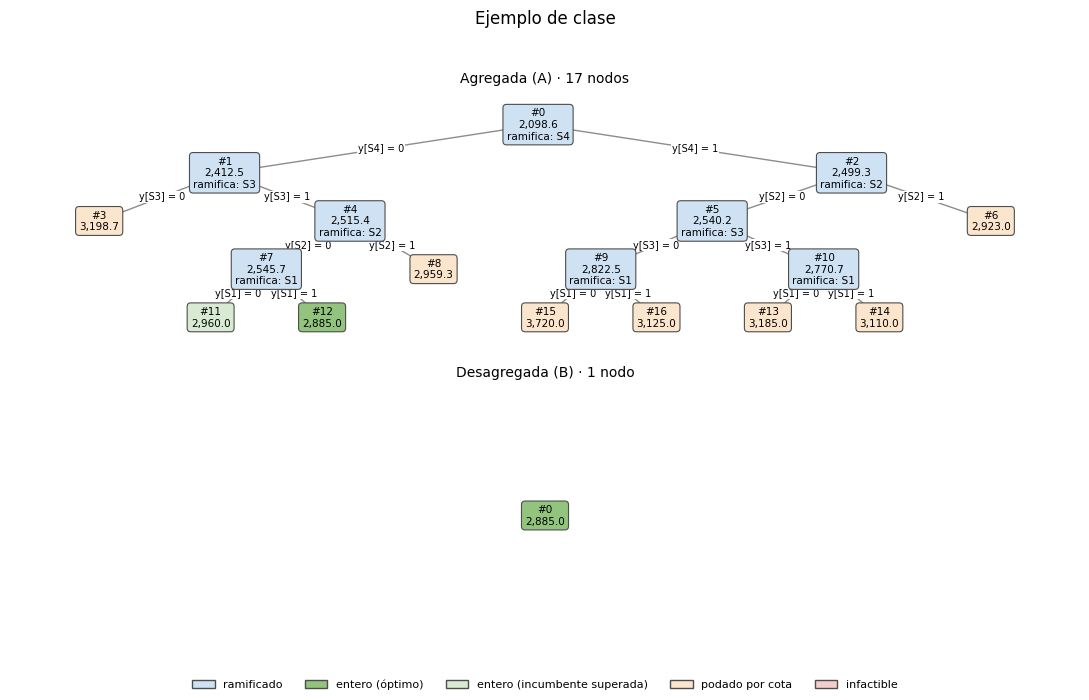

In [11]:
def datos_clase():
    """Ejemplo de clase (cuaderno 02_Formulaciones): sitios candidatos y faenas, sin capacidades."""
    fijo = {"S1": 450, "S2": 550, "S3": 375, "S4": 625}                  # millones al año
    dem = {"F1": 30, "F2": 45, "F3": 25, "F4": 60, "F5": 40, "F6": 35, "F7": 50, "F8": 20}   # kt
    ct = {("S1", "F1"): 4,  ("S1", "F2"): 6,  ("S1", "F3"): 9,  ("S1", "F4"): 12,
          ("S1", "F5"): 15, ("S1", "F6"): 11, ("S1", "F7"): 18, ("S1", "F8"): 20,
          ("S2", "F1"): 8,  ("S2", "F2"): 5,  ("S2", "F3"): 6,  ("S2", "F4"): 7,
          ("S2", "F5"): 10, ("S2", "F6"): 14, ("S2", "F7"): 13, ("S2", "F8"): 16,
          ("S3", "F1"): 14, ("S3", "F2"): 11, ("S3", "F3"): 7,  ("S3", "F4"): 5,
          ("S3", "F5"): 6,  ("S3", "F6"): 9,  ("S3", "F7"): 8,  ("S3", "F8"): 12,
          ("S4", "F1"): 19, ("S4", "F2"): 17, ("S4", "F3"): 13, ("S4", "F4"): 10,
          ("S4", "F5"): 7,  ("S4", "F6"): 5,  ("S4", "F7"): 6,  ("S4", "F8"): 4}
    D = float(sum(dem.values()))
    return {"nombre": "clase", "escenario": "clase", "k": 0, "costo_constante": 0.0,
            "fuentes": [{"id": s, "U": D, "F": float(fijo[s]), "cuenta_respaldo": False} for s in fijo],
            "puntos": [{"id": f, "d": float(dem[f])} for f in dem],
            "c": {s: {f: float(ct[(s, f)]) for f in dem} for s in fijo}}


clase = datos_clase()
RESULTADOS_CLASE = {form: branch_and_bound(clase, form, ESTRATEGIA_BB) for form in FORMULACIONES_BB}

# las cifras que publica el cuaderno del profesor
assert abs(RESULTADOS_CLASE["A"]["cota_raiz"] - 2098.61) < 0.01, "la relajación agregada no reproduce 2.098,61"
assert abs(RESULTADOS_CLASE["B"]["cota_raiz"] - 2885.00) < 0.01, "la relajación desagregada no reproduce 2.885,00"
assert all(abs(r["optimo"] - 2885.00) < 0.01 for r in RESULTADOS_CLASE.values()), "el óptimo entero no es 2.885,00"
print("Validación correcta: el código reproduce 2.098,61 (agregada), 2.885,00 (desagregada) y el óptimo 2.885,00.")

resumen_clase = pd.DataFrame([{"formulacion": f, **resumen_arbol(r)} for f, r in RESULTADOS_CLASE.items()])
resumen_clase.to_csv(os.path.join(DIR["resultados"], "bb_validacion_clase.csv"), index=False)
display(resumen_clase.round(2).style.format(na_rep="—"))

figura_arboles([("Agregada (A)", RESULTADOS_CLASE["A"]), ("Desagregada (B)", RESULTADOS_CLASE["B"])],
               "Ejemplo de clase", os.path.join(DIR["figuras"], "bb_clase.png"), ncols=1)

Con la agregada el árbol necesita 17 nodos para demostrar el óptimo; con la desagregada la relajación ya es entera. A0 coincide con A y AB con B, porque aquí la capacidad no restringe.

### 5.2 Hospital: brecha y tamaño del árbol

| Caso | Qué es |
|---|---|
| Ampliado | Caso principal: ramales por sector, mantención por ramal, cilindros flexibles y cobertura doble (sección 3.2) |
| Real | Datos del hospital, sin esos rasgos |

In [12]:
def generar_caso(escenario, llenados, nombre):
    """Instancia de un caso del B&B, independiente del escenario elegido en la configuración."""
    global REPOSICIONES_ESTANQUE
    guardado, REPOSICIONES_ESTANQUE = REPOSICIONES_ESTANQUE, llenados
    try:
        generador = generar_real if escenario == "real" else generar_ampliado
        datos = generador(nombre, k=K_RESPALDO)
    finally:
        REPOSICIONES_ESTANQUE = guardado
    verificar_instancia(datos)
    return datos


RESULTADOS_BB, filas = {}, []
for clave, (etiqueta, escenario, llenados) in CASOS_BB.items():
    for nombre in INSTANCIAS_BB:
        datos = generar_caso(escenario, llenados, nombre)
        for form in FORMULACIONES_BB:
            r = branch_and_bound(datos, form, ESTRATEGIA_BB)
            RESULTADOS_BB[(clave, nombre, form)] = r
            filas.append({"caso": etiqueta, "instancia": nombre, "formulacion": form,
                          **resumen_arbol(r), "verificado_vs_HiGHS": "pendiente"})
        # equivalencia en acción: todas las formulaciones deben llegar al mismo óptimo entero
        optimos = [RESULTADOS_BB[(clave, nombre, f)]["optimo"] for f in FORMULACIONES_BB]
        assert max(optimos) - min(optimos) <= 1e-6 * abs(optimos[0]), \
            f"{etiqueta} {nombre}: las formulaciones difieren en el óptimo: {optimos}"

resumen_bb = pd.DataFrame(filas)
resumen_bb.to_csv(os.path.join(DIR["resultados"], "bb_resumen.csv"), index=False)

for valor, titulo in [("brecha_relaj_%", "Brecha de la relajación lineal (%)"),
                      ("nodos", "Nodos del árbol (todos los LP resueltos)")]:
    print(f"\n{titulo}")
    display(resumen_bb.pivot_table(index=["caso", "instancia"], columns="formulacion",
                                   values=valor, sort=False).reindex(columns=FORMULACIONES_BB).round(2))


Brecha de la relajación lineal (%)


formulacion                                        A    B    A0   AB
caso                                 instancia                      
Ampliado · ramales y cobertura doble I1         0.00  0.0  0.10  0.0
                                     I2         0.73  0.0  0.83  0.0
Real · datos del hospital            I1         0.00  0.0  0.00  0.0
                                     I2         0.00  0.0  0.00  0.0


Nodos del árbol (todos los LP resueltos)


formulacion                                       A    B   A0   AB
caso                                 instancia                    
Ampliado · ramales y cobertura doble I1         1.0  1.0  3.0  1.0
                                     I2         3.0  1.0  5.0  1.0
Real · datos del hospital            I1         1.0  1.0  1.0  1.0
                                     I2         1.0  1.0  1.0  1.0

**Lectura**

- **Real:** brecha nula en todas las formulaciones. Indura es la fuente más barata para todos los puntos y el respaldo obliga a pagar al menos un costo fijo de estanque, así que toda relajación cuesta al menos lo mismo que la solución entera: los vínculos no intervienen.
- **Ampliado:** Pabellón solo puede recibir de T1, que así es necesario para una parte pequeña de la demanda. La agregada deja abrir T1 en una fracción mínima; la desagregada lo obliga a abrirse completo y cierra la brecha. En I2 el árbol pasa de 5 nodos (A0) a 3 (A) y a 1 (B y AB).

Una cota raíz más alta significa menos trabajo potencial, pero el número de nodos depende también de la regla de ramificación; con una sola regla, estos conteos no deben generalizarse.

### 5.3 Registro de nodos

Una fila por nodo, en el orden en que se crearon: la decisión que llevó a él, la cota de su LP, las habilitaciones fraccionarias y cómo terminó.

In [13]:
for clave in CASOS_ARBOL:
    print(f"\n{'=' * 8} {CASOS_BB[clave][0]} {'=' * 8}")
    for nombre in INSTANCIAS_BB[:1]:                 # registro completo solo para la primera instancia
        for form in FORMULACIONES_BB:
            r = RESULTADOS_BB[(clave, nombre, form)]
            print(f"\n{nombre} · formulación {form} · {r['n_nodos']} {'nodo' if r['n_nodos'] == 1 else 'nodos'} · "
                  f"cota raíz {formato_valor(r['cota_raiz'])} → óptimo {formato_valor(r['optimo'])}")
            display(registro_nodos(r))


======== Ampliado · ramales y cobertura doble ========

I1 · formulación A · 1 nodo · cota raíz 26.477 M → óptimo 26.477 M


,nodo,padre,prof,decisión,cota LP,y fraccionarias,estado,ramifica en
0,0,—,0,raíz,26.477 M,—,entero (óptimo),—



I1 · formulación B · 1 nodo · cota raíz 26.477 M → óptimo 26.477 M


,nodo,padre,prof,decisión,cota LP,y fraccionarias,estado,ramifica en
0,0,—,0,raíz,26.477 M,—,entero (óptimo),—



I1 · formulación A0 · 3 nodos · cota raíz 26.450 M → óptimo 26.477 M


,nodo,padre,prof,decisión,cota LP,y fraccionarias,estado,ramifica en
0,0,—,0,raíz,26.450 M,T2=0.983,ramificado,T2
1,1,0,1,y[T2] = 0,—,—,infactible,—
2,2,0,1,y[T2] = 1,26.477 M,—,entero (óptimo),—



I1 · formulación AB · 1 nodo · cota raíz 26.477 M → óptimo 26.477 M


,nodo,padre,prof,decisión,cota LP,y fraccionarias,estado,ramifica en
0,0,—,0,raíz,26.477 M,—,entero (óptimo),—


### 5.4 Árboles

Cada caja es un nodo: número, cota del LP y, si se ramifica, la variable elegida. Cada arista lleva la decisión que se tomó.

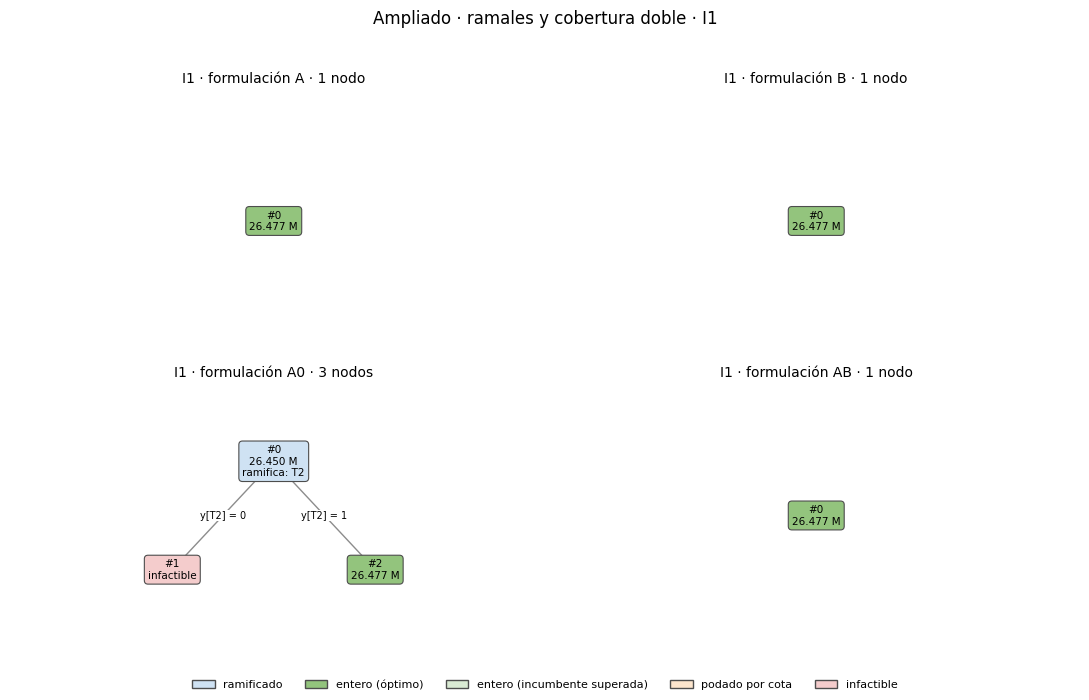

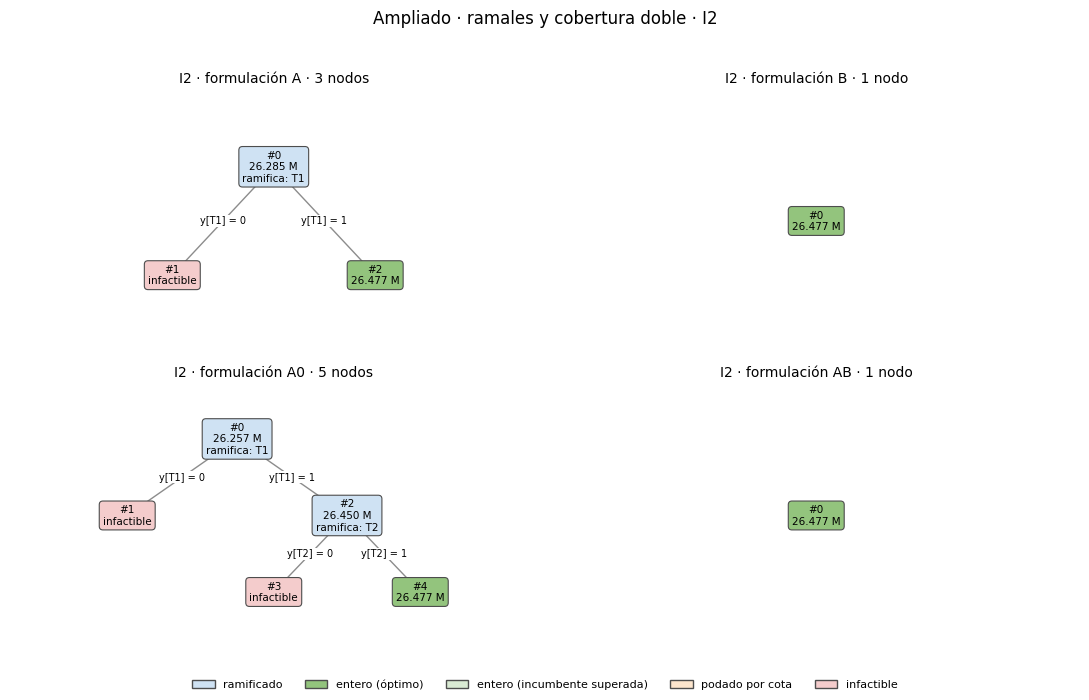

In [14]:
for clave in CASOS_ARBOL:
    for nombre in INSTANCIAS_BB:
        lista = [(f"{nombre} · formulación {form}", RESULTADOS_BB[(clave, nombre, form)])
                 for form in FORMULACIONES_BB]
        figura_arboles(lista, f"{CASOS_BB[clave][0]} · {nombre}",
                       os.path.join(DIR["figuras"], f"bb_{clave}_{nombre}.png"))

## 6. Resolución y medición

Cada modelo de Pyomo se escribe en formato LP y se resuelve con HiGHS mediante `highspy`.

| Indicador | Origen |
|---|---|
| Valor óptimo, cota dual, brecha de optimalidad final y nodos | `getInfo()` de HiGHS |
| Variables, restricciones y no nulos | Modelo leído por HiGHS, antes del presolve |
| Cortes generados y activos, cota raíz | Registro de resolución |
| Tiempo | `time.perf_counter()` alrededor de `run()`; excluye construir y leer el modelo |

**Definiciones operativas.** Cortes generados: máximo de la columna `Cuts` del registro. Cortes activos: `InLp` en la última fila. Cota raíz: el mayor `BestBound` antes de procesar el primer nodo. Si el registro no la informa y la relajación ya es entera, se deduce, porque z_LP ≤ cota raíz ≤ z_entero; si no, queda vacía.

In [15]:
# Una fila de la tabla de progreso de HiGHS: indicador de origen opcional y luego 12 columnas.
_FILA_PROGRESO = re.compile(r"^\s*([A-Za-z]\s+)?\d+\s+\d+\s+\d+\s+[\d.]+%\s+.*\s[\d.]+s\s*$")


def _a_numero(texto):
    try:
        x = float(texto.rstrip("%"))
    except ValueError:
        return math.nan   # 'Large'
    return x if math.isfinite(x) else math.nan   # Python lee 'inf' y '-inf' como números; aquí no son cotas


def leer_registro(texto):
    """Extrae cortes y cota raíz de la tabla de progreso del registro de HiGHS."""
    filas = []
    for linea in texto.splitlines():
        if not _FILA_PROGRESO.match(linea):
            continue
        t = linea.split()
        if not t[0].isdigit():      # descarta el indicador de origen (J, L, T, ...)
            t = t[1:]
        if len(t) != 12:
            continue
        # columnas: Proc InQueue Leaves Expl BestBound BestSol Gap Cuts InLp Confl LpIters Time
        filas.append({"proc": int(t[0]), "cota": _a_numero(t[4]),
                      "cuts": int(t[7]), "inlp": int(t[8])})
    if not filas:   # problema resuelto en el presolve, o un LP
        return {"cortes_gen": 0, "cortes_act": 0, "cota_raiz": math.nan, "filas_registro": 0}
    # cota raíz: la mayor cota informada mientras no se ha procesado ningún nodo
    cotas_raiz = [f["cota"] for f in filas if f["proc"] == 0 and not math.isnan(f["cota"])]
    return {"cortes_gen": max(f["cuts"] for f in filas),
            "cortes_act": filas[-1]["inlp"],
            "cota_raiz": max(cotas_raiz) if cotas_raiz else math.nan,
            "filas_registro": len(filas)}


def escribir_lp(modelo, ruta):
    """Escribe el modelo en formato LP y devuelve su número de variables binarias."""
    modelo.write(ruta, io_options={"symbolic_solver_labels": False})
    return sum(1 for v in modelo.component_data_objects(pyo.Var) if v.is_binary())


def resolver_lp(ruta_lp, ruta_registro, limite_tiempo):
    """Resuelve un archivo LP con HiGHS y devuelve un diccionario de indicadores."""
    if os.path.exists(ruta_registro):
        os.remove(ruta_registro)
    h = highspy.Highs()
    h.setOptionValue("output_flag", True)          # opciones de salida, no del algoritmo
    h.setOptionValue("log_to_console", False)
    h.setOptionValue("log_file", ruta_registro)
    h.setOptionValue("time_limit", float(limite_tiempo))
    h.readModel(ruta_lp)

    n_var, n_res = h.getNumCol(), h.getNumRow()
    try:
        n_nz = h.getNumNz()
    except AttributeError:
        n_nz = len(h.getLp().a_matrix_.value_)

    t0 = time.perf_counter()
    h.run()
    tiempo = time.perf_counter() - t0

    estado = h.modelStatusToString(h.getModelStatus())
    info = h.getInfo()
    resultado = {
        "estado": estado,
        "z": info.objective_function_value if estado in ("Optimal", "Time limit reached") else math.nan,
        "cota_dual": info.mip_dual_bound,
        "brecha_opt": info.mip_gap,
        "nodos": info.mip_node_count,
        "tiempo_s": tiempo,
        "n_var": n_var, "n_res": n_res, "n_nz": n_nz,
    }
    del h          # cierra el archivo de registro antes de leerlo
    gc.collect()
    with open(ruta_registro, encoding="utf-8", errors="replace") as f:
        resultado.update(leer_registro(f.read()))
    return resultado

## 7. Verificación numérica de la equivalencia

Complementa el argumento algebraico del README. Para cada combinación de y ∈ {0, 1}^|S| de I1 (8) e I2 (64) se fija y y se resuelve el problema en x con cada formulación: el estado (factible o no) y el costo deben coincidir. Además, los óptimos enteros del experimento deben coincidir dentro de `TOL_EQUIV` en todas las instancias (sección 9).

In [16]:
def verificar_equivalencia_exhaustiva(datos, formulaciones, tol=1e-6):
    """Fija cada combinación binaria de y y compara estado y costo entre formulaciones."""
    S = [f["id"] for f in datos["fuentes"]]
    discrepancias, n_factibles = [], 0
    for combo in itertools.product([0, 1], repeat=len(S)):
        valor_y = dict(zip(S, combo))
        res = {}
        for form in formulaciones:
            m = construir(datos, form)
            m.fijar_y = pyo.Constraint(m.S, rule=lambda m, s: m.y[s] == valor_y[s])
            base = f"{datos['nombre']}_{form}_equiv"
            ruta_lp = os.path.join(DIR["lp"], base + ".lp")
            escribir_lp(m, ruta_lp)
            r = resolver_lp(ruta_lp, os.path.join(DIR["registros"], base + ".log"), 60)
            res[form] = (r["estado"], r["z"])
        estados = {e for e, _ in res.values()}
        costos = [z for e, z in res.values() if e == "Optimal"]
        iguales = len(estados) == 1 and (
            not costos or max(costos) - min(costos) <= tol * max(1.0, abs(costos[0])))
        n_factibles += "Optimal" in estados
        if not iguales:
            discrepancias.append((combo, res))
    return 2 ** len(S), n_factibles, discrepancias


filas = []
for nombre in [i for i in INSTANCIAS if len(DATOS[i]["fuentes"]) <= 6]:
    total, factibles, disc = verificar_equivalencia_exhaustiva(DATOS[nombre], FORMULACIONES)
    filas.append({"instancia": nombre, "combinaciones de y": total,
                  "factibles": factibles, "discrepancias": len(disc)})
    for combo, res in disc:
        print(f"DISCREPANCIA en {nombre}, y = {combo}: {res}")
equivalencia_exhaustiva = pd.DataFrame(filas)
equivalencia_exhaustiva.to_csv(os.path.join(DIR["resultados"], "equivalencia_exhaustiva.csv"), index=False)
assert equivalencia_exhaustiva["discrepancias"].sum() == 0, "las formulaciones NO son equivalentes"
equivalencia_exhaustiva

,instancia,combinaciones de y,factibles,discrepancias
0,I1,8,1,0
1,I2,64,15,0


## 8. Experimento

Primero las relajaciones lineales, una vez por instancia y formulación, porque son deterministas. Luego los modelos enteros, con `REPETICIONES` ejecuciones cada uno, en el mismo equipo, con los parámetros por defecto de HiGHS y el mismo límite de tiempo. El orden de las formulaciones rota en cada repetición, para que una variación de carga de la máquina no favorezca a ninguna. Cada resolución se guarda al terminar: si Colab se desconecta, la ejecución se retoma sin repetir trabajo (para empezar de cero, borrar `taller2_<escenario>/resultados`).

In [17]:
RUTA_RELAJ = os.path.join(DIR["resultados"], "relajaciones.csv")
RUTA_CORRIDAS = os.path.join(DIR["resultados"], "corridas.csv")


def cargar_csv(ruta):
    return pd.read_csv(ruta) if os.path.exists(ruta) else pd.DataFrame()


def agregar_fila(ruta, fila):
    pd.DataFrame([fila]).to_csv(ruta, mode="a", header=not os.path.exists(ruta), index=False)


# ---------- 7.1 relajaciones lineales ----------
hechas = cargar_csv(RUTA_RELAJ)
claves = set(zip(hechas.get("instancia", []), hechas.get("formulacion", [])))
for nombre in INSTANCIAS:
    for form in FORMULACIONES:
        if (nombre, form) in claves:
            continue
        base = f"{nombre}_{form}_relajado"
        ruta_lp = os.path.join(DIR["lp"], base + ".lp")
        escribir_lp(construir(DATOS[nombre], form, relajado=True), ruta_lp)
        r = resolver_lp(ruta_lp, os.path.join(DIR["registros"], base + ".log"), LIMITE_TIEMPO)
        agregar_fila(RUTA_RELAJ, {"instancia": nombre, "formulacion": form,
                                  "estado_lp": r["estado"], "z_lp": r["z"], "tiempo_lp_s": r["tiempo_s"]})
        print(f"relajación  {nombre:<3} {form:<3} z_LP = {r['z']:12.2f}")

# ---------- 7.2 modelos enteros ----------
hechas = cargar_csv(RUTA_CORRIDAS)
claves = set(zip(hechas.get("instancia", []), hechas.get("formulacion", []), hechas.get("rep", [])))
for nombre in INSTANCIAS:
    rutas_lp, binarias = {}, {}
    for rep in range(REPETICIONES):
        orden = FORMULACIONES[rep % len(FORMULACIONES):] + FORMULACIONES[:rep % len(FORMULACIONES)]
        for form in orden:
            if (nombre, form, rep) in claves:
                continue
            if form not in rutas_lp:     # el archivo LP se escribe una vez y se reutiliza
                rutas_lp[form] = os.path.join(DIR["lp"], f"{nombre}_{form}_entero.lp")
                binarias[form] = escribir_lp(construir(DATOS[nombre], form), rutas_lp[form])
            ruta_reg = os.path.join(DIR["registros"], f"{nombre}_{form}_rep{rep}.log")
            r = resolver_lp(rutas_lp[form], ruta_reg, LIMITE_TIEMPO)
            agregar_fila(RUTA_CORRIDAS, {"instancia": nombre, "formulacion": form, "rep": rep,
                                         "n_bin": binarias[form], **r})
            print(f"entero      {nombre:<3} {form:<3} rep {rep}  {r['estado']:<20} "
                  f"z = {r['z']:12.2f}  nodos = {r['nodos']:>6}  t = {r['tiempo_s']:8.2f} s")

relajación  I1  A   z_LP =  26477187.83
relajación  I1  B   z_LP =  26477187.83
relajación  I1  A0  z_LP =  26450238.15
relajación  I1  AB  z_LP =  26477187.83
relajación  I2  A   z_LP =  26285020.20
relajación  I2  B   z_LP =  26477187.83
relajación  I2  A0  z_LP =  26257211.28
relajación  I2  AB  z_LP =  26477187.83
relajación  I3  A   z_LP =  26285020.07
relajación  I3  B   z_LP =  26477187.69
relajación  I3  A0  z_LP =  26257211.16
relajación  I3  AB  z_LP =  26477187.69
relajación  I4  A   z_LP =  26285020.02
relajación  I4  B   z_LP =  26477187.65
relajación  I4  A0  z_LP =  26257211.11
relajación  I4  AB  z_LP =  26477187.65
entero      I1  A   rep 0  Optimal              z =  26477187.83  nodos =      0  t =     0.00 s
entero      I1  B   rep 0  Optimal              z =  26477187.83  nodos =      0  t =     0.00 s
entero      I1  A0  rep 0  Optimal              z =  26477187.83  nodos =      0  t =     0.00 s
entero      I1  AB  rep 0  Optimal              z =  26477187.83  nod

## 9. Resultados

Una fila por instancia y formulación. Las brechas usan como referencia z_ref, el mejor óptimo entero de la instancia.

| Columna | Significado |
|---|---|
| `z_ent`, `z_total` | Óptimo entero del modelo; `z_total` suma la reserva de cilindros |
| `brecha_relaj_%` | (z_ref − z_LP) / z_ref: calidad de la formulación, sin intervención del solver |
| `cociente_integralidad` | z_ref / z_LP |
| `brecha_raiz_%` | Brecha después del presolve y los cortes en la raíz |
| `cierre_raiz_%` | Parte de la brecha de la relajación cerrada por el solver en la raíz ("—" si no había brecha) |
| `brecha_opt_final_%` | Brecha de optimalidad al detenerse; distinta de cero solo si se alcanza el límite de tiempo |
| `equivalencia_ok` | Si los óptimos enteros de la instancia coinciden dentro de `TOL_EQUIV` |

In [18]:
def construir_tabla(relaj, corridas):
    g = corridas.groupby(["instancia", "formulacion"])
    t = g.agg(estado=("estado", lambda s: s.mode().iat[0]),
              reps=("rep", "count"),
              n_var=("n_var", "first"), n_bin=("n_bin", "first"),
              n_res=("n_res", "first"), n_nz=("n_nz", "first"),
              z_ent=("z", "mean"),
              cota_raiz=("cota_raiz", "mean"),
              nodos=("nodos", "mean"),
              cortes_gen=("cortes_gen", "mean"),
              cortes_act=("cortes_act", "mean"),
              tiempo_media_s=("tiempo_s", "mean"),
              tiempo_de_s=("tiempo_s", "std"),
              brecha_opt_final=("brecha_opt", "mean")).reset_index()
    t = t.merge(relaj[["instancia", "formulacion", "z_lp"]], on=["instancia", "formulacion"])

    # referencia: mejor óptimo entero conocido de cada instancia
    optimas = corridas[corridas["estado"] == "Optimal"]
    z_ref = optimas.groupby("instancia")["z"].min()
    z_ref = z_ref.reindex(t["instancia"].unique()).fillna(corridas.groupby("instancia")["z"].min())
    t["z_ref"] = t["instancia"].map(z_ref)

    constante = {n: DATOS[n].get("costo_constante", 0.0) for n in DATOS}
    t["z_total"] = t["z_ent"] + t["instancia"].map(constante)
    t["brecha_relaj_%"] = 100 * (t["z_ref"] - t["z_lp"]) / t["z_ref"]
    t["cociente_integralidad"] = t["z_ref"] / t["z_lp"]
    # una cota raíz real nunca es peor que la relajación lineal; si lo es, el registro
    # no mostró la fila posterior al LP (ocurre cuando todo se resuelve en la raíz)
    invalida = t["cota_raiz"] < t["z_lp"] - 1e-6 * t["z_lp"].abs()
    t.loc[invalida, "cota_raiz"] = math.nan
    t["cota_raiz_origen"] = "registro"
    t.loc[t["cota_raiz"].isna(), "cota_raiz_origen"] = "no reportada"
    # si la relajación ya es entera, z_LP <= cota raíz <= z_ent fuerza la igualdad
    sin_brecha = (t["z_ref"] - t["z_lp"]).abs() <= 1e-7 * t["z_ref"].abs()
    deducible = t["cota_raiz"].isna() & sin_brecha
    t.loc[deducible, "cota_raiz"] = t.loc[deducible, "z_ref"]
    t.loc[deducible, "cota_raiz_origen"] = "deducida"
    t["brecha_raiz_%"] = 100 * (t["z_ref"] - t["cota_raiz"]) / t["z_ref"]
    brecha_abs = t["z_ref"] - t["z_lp"]
    # si la relajación ya alcanza el óptimo entero, no hay brecha que cerrar
    t["cierre_raiz_%"] = (100 * (t["cota_raiz"] - t["z_lp"]) / brecha_abs.where(
        brecha_abs > 1e-7 * t["z_ref"].abs())).clip(lower=0)
    for col in ["brecha_relaj_%", "brecha_raiz_%"]:   # elimina ruido numérico del orden de 1e-10
        t.loc[t[col].abs() < 1e-7, col] = 0.0
    t["brecha_opt_final_%"] = 100 * t["brecha_opt_final"].where(t["estado"] != "Optimal", 0.0)

    # equivalencia numérica: dispersión relativa de los óptimos enteros por instancia
    dispersion = optimas.groupby("instancia")["z"].agg(lambda s: (s.max() - s.min()) / abs(s.min()))
    t["equivalencia_ok"] = t["instancia"].map(dispersion <= TOL_EQUIV)

    orden_inst = {n: i for i, n in enumerate(INSTANCIAS)}
    orden_form = {f: i for i, f in enumerate(FORMULACIONES)}
    t = t.sort_values(by=["instancia", "formulacion"],
                      key=lambda col: col.map(orden_inst if col.name == "instancia" else orden_form))
    columnas = ["instancia", "formulacion", "estado", "reps", "n_var", "n_bin", "n_res", "n_nz",
                "z_lp", "z_ent", "z_total", "brecha_relaj_%", "cociente_integralidad", "cota_raiz",
                "cota_raiz_origen", "brecha_raiz_%", "cierre_raiz_%", "nodos", "cortes_gen", "cortes_act",
                "tiempo_media_s", "tiempo_de_s", "brecha_opt_final_%", "equivalencia_ok"]
    return t[columnas].reset_index(drop=True)


relaj = cargar_csv(RUTA_RELAJ)
corridas = cargar_csv(RUTA_CORRIDAS)
relaj = relaj[relaj["instancia"].isin(INSTANCIAS) & relaj["formulacion"].isin(FORMULACIONES)]
corridas = corridas[corridas["instancia"].isin(INSTANCIAS) & corridas["formulacion"].isin(FORMULACIONES)]

tabla = construir_tabla(relaj, corridas)
tabla.to_csv(os.path.join(DIR["resultados"], "tabla_resultados.csv"), index=False)

if not tabla["equivalencia_ok"].fillna(False).all():
    print("ATENCIÓN: hay instancias cuyos óptimos enteros no coinciden. Revisar antes de interpretar.")
# En pantalla, "—" indica un valor no definido; el CSV conserva las celdas vacías.
tabla.round({"z_lp": 2, "z_ent": 2, "z_total": 2, "brecha_relaj_%": 2, "cociente_integralidad": 4, "cota_raiz": 2,
             "brecha_raiz_%": 2, "cierre_raiz_%": 1, "nodos": 1, "cortes_gen": 1, "cortes_act": 1,
             "tiempo_media_s": 3, "tiempo_de_s": 3, "brecha_opt_final_%": 3}
            ).style.format(na_rep="—", precision=4)

,instancia,formulacion,estado,reps,n_var,n_bin,n_res,n_nz,z_lp,z_ent,z_total,brecha_relaj_%,cociente_integralidad,cota_raiz,cota_raiz_origen,brecha_raiz_%,cierre_raiz_%,nodos,cortes_gen,cortes_act,tiempo_media_s,tiempo_de_s,brecha_opt_final_%,equivalencia_ok
0,I1,A,Optimal,3,10,3,12,31,26477187.8300,26477187.8300,27677187.8300,0.0000,1.0000,26477187.8300,registro,0.0000,—,0.0000,0.0000,0.0000,0.0010,0.0000,0.0000,True
1,I1,B,Optimal,3,10,3,16,35,26477187.8300,26477187.8300,27677187.8300,0.0000,1.0000,26477187.8300,registro,0.0000,—,0.0000,0.0000,0.0000,0.0010,0.0000,0.0000,True
2,I1,A0,Optimal,3,10,3,12,31,26450238.1500,26477187.8300,27677187.8300,0.1000,1.0010,26477187.8300,registro,0.0000,100.0000,0.0000,0.0000,0.0000,0.0010,0.0000,0.0000,True
3,I1,AB,Optimal,3,10,3,19,45,26477187.8300,26477187.8300,27677187.8300,0.0000,1.0000,26477187.8300,registro,0.0000,—,0.0000,0.0000,0.0000,0.0010,0.0000,0.0000,True
4,I2,A,Optimal,3,54,6,24,163,26285020.2000,26477187.8300,27677187.8300,0.7300,1.0073,26477187.8300,registro,0.0000,100.0000,0.0000,0.0000,0.0000,0.0010,0.0000,0.0000,True
5,I2,B,Optimal,3,54,6,66,205,26477187.8300,26477187.8300,27677187.8300,0.0000,1.0000,26477187.8300,registro,0.0000,—,0.0000,0.0000,0.0000,0.0010,0.0000,0.0000,True
6,I2,A0,Optimal,3,54,6,24,163,26257211.2800,26477187.8300,27677187.8300,0.8300,1.0084,26477187.8300,registro,0.0000,100.0000,0.0000,0.0000,0.0000,0.0010,0.0000,0.0000,True
7,I2,AB,Optimal,3,54,6,72,259,26477187.8300,26477187.8300,27677187.8300,0.0000,1.0000,26477187.8300,registro,0.0000,—,0.0000,0.0000,0.0000,0.0020,0.0000,0.0000,True
8,I3,A,Optimal,3,359,12,58,1078,26285020.0700,26477187.6900,27677187.6900,0.7300,1.0073,—,no reportada,—,—,1.0000,0.0000,0.0000,0.0120,0.0040,0.0000,True
9,I3,B,Optimal,3,359,12,393,1413,26477187.6900,26477187.6900,27677187.6900,0.0000,1.0000,26477187.6900,deducida,0.0000,—,1.0000,0.0000,0.0000,0.0140,0.0050,0.0000,True


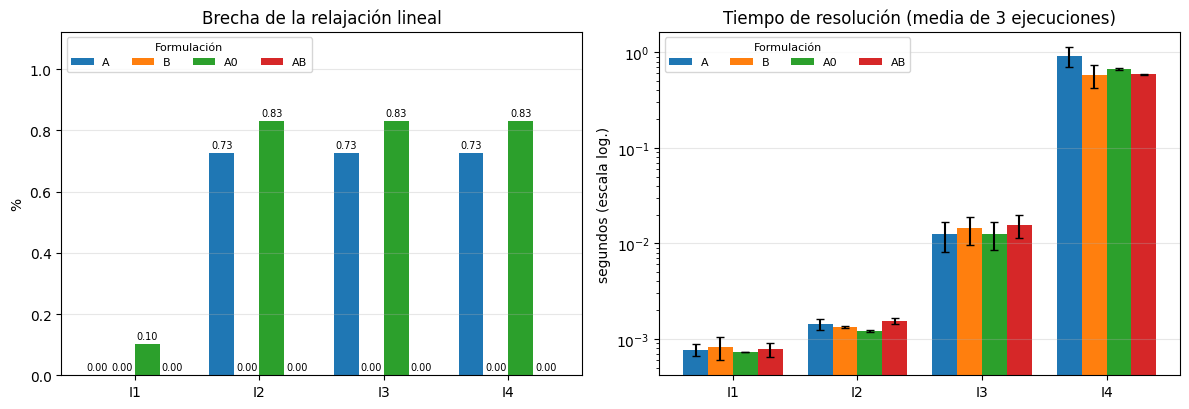

In [19]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
ancho = 0.8 / len(FORMULACIONES)
posiciones = range(len(INSTANCIAS))

for i, form in enumerate(FORMULACIONES):
    sub = tabla[tabla["formulacion"] == form].set_index("instancia").reindex(INSTANCIAS)
    x = [p + (i - (len(FORMULACIONES) - 1) / 2) * ancho for p in posiciones]
    barras = ejes[0].bar(x, sub["brecha_relaj_%"], width=ancho, label=form)
    ejes[0].bar_label(barras, fmt="%.2f", fontsize=7, padding=2)   # el valor se lee aunque la barra mida cero
    ejes[1].bar(x, sub["tiempo_media_s"], width=ancho, yerr=sub["tiempo_de_s"].fillna(0),
                capsize=3, label=form)

maxima = tabla["brecha_relaj_%"].max()
ejes[0].set(title="Brecha de la relajación lineal", ylabel="%", ylim=(0, max(1.0, 1.35 * maxima)))
if maxima < 1e-9:
    ejes[0].text(0.5, 0.5, "Brecha = 0 % en todas las instancias:\nla relajación lineal ya es entera",
                 transform=ejes[0].transAxes, ha="center", va="center", fontsize=10, color="0.35")
ejes[1].set(title=f"Tiempo de resolución (media de {REPETICIONES} ejecuciones)",
            ylabel="segundos (escala log.)", yscale="log")
for ax in ejes:
    ax.set_xticks(list(posiciones))
    ax.set_xticklabels(INSTANCIAS)
    ax.legend(title="Formulación", loc="upper left", ncol=len(FORMULACIONES), fontsize=8, title_fontsize=8)
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(DIR["figuras"], "brecha_y_tiempo.png"), dpi=200)
plt.show()

### 9.1 Verificación cruzada del branch and bound con HiGHS

Para los casos de la sección 5 que coinciden con la configuración, la cota raíz del árbol debe ser la relajación lineal de HiGHS y el óptimo debe ser el mismo. Si no coinciden, el cuaderno se detiene.

In [20]:
def referencia_highs(nombre, form):
    """(z_LP, z_entero) del experimento de HiGHS, o None si no hay corrida de esa instancia."""
    r = relaj[(relaj["instancia"] == nombre) & (relaj["formulacion"] == form)]
    e = corridas[(corridas["instancia"] == nombre) & (corridas["formulacion"] == form)
                 & (corridas["estado"] == "Optimal")]
    return None if r.empty or e.empty else (r["z_lp"].iloc[0], e["z"].mean())


clave_de = {v[0]: k for k, v in CASOS_BB.items()}
verificado = []
for _, fila in resumen_bb.iterrows():
    _, escenario, llenados = CASOS_BB[clave_de[fila["caso"]]]
    coincide = escenario == ESCENARIO and llenados == REPOSICIONES_ESTANQUE
    ref = referencia_highs(fila["instancia"], fila["formulacion"]) if coincide else None
    if ref is None:
        verificado.append("no aplica")
        continue
    z_lp, z_ent = ref
    assert abs(fila["cota_raiz"] - z_lp) <= 1e-6 * abs(z_lp), \
        f"{fila['caso']} {fila['instancia']} {fila['formulacion']}: cota raíz {fila['cota_raiz']:.2f} distinta de la de HiGHS {z_lp:.2f}"
    assert abs(fila["optimo"] - z_ent) <= TOL_EQUIV * abs(z_ent), \
        f"{fila['caso']} {fila['instancia']} {fila['formulacion']}: óptimo {fila['optimo']:.2f} distinto del de HiGHS {z_ent:.2f}"
    verificado.append("sí")

resumen_bb["verificado_vs_HiGHS"] = verificado
resumen_bb.to_csv(os.path.join(DIR["resultados"], "bb_resumen.csv"), index=False)
n_ok = verificado.count("sí")
if n_ok:
    print(f"{n_ok} comparaciones con HiGHS: la cota raíz y el óptimo coinciden en todas.")
else:
    print("Ningún caso del branch and bound coincide con la configuración actual; no hay comparación con HiGHS.")

8 comparaciones con HiGHS: la cota raíz y el óptimo coinciden en todas.


### 9.2 Solución óptima y relajación en la raíz

La primera tabla muestra qué fuentes habilita la solución óptima, cuánto entrega cada una a cada servicio y su costo; la suma reproduce el óptimo de HiGHS. La segunda muestra, para cada formulación, cuánto se habilita cada estanque en la relajación lineal de la raíz: ahí se ve el mecanismo que separa a las formulaciones. La celda se detiene si alguna cifra no coincide con las de HiGHS.

In [22]:
# ---- 9.2 Solución óptima y relajación en la raíz ----
SERVICIOS = {"PAB": "Pabellón", "UPC": "UPC", "HOSP": "Hospitalización"}

# Solución óptima: se resuelve con AB, se fijan las y óptimas y se recuperan los flujos x.
filas_sol = []
for nombre in INSTANCIAS:
    datos = DATOS[nombre]
    r = branch_and_bound(datos, "AB", ESTRATEGIA_BB)
    lp = armar_lp(datos, "AB")
    y = [float(v) for v in r["y"]]
    res = linprog(lp["c"], A_ub=lp["A_ub"], b_ub=lp["b_ub"], A_eq=lp["A_eq"], b_eq=lp["b_eq"],
                  bounds=[(0, u) for u in lp["ub_x"]] + [(v, v) for v in y], method="highs")
    assert res.status == 0, f"{nombre}: no se pudo recuperar la solución óptima"
    nC = len(datos["puntos"])
    x = res.x[:lp["nx"]].reshape(lp["nS"], nC)
    costo_x = lp["c"][:lp["nx"]].reshape(lp["nS"], nC)
    servicio = [p["servicio"] for p in datos["puntos"]]

    z_highs = tabla.loc[tabla["instancia"] == nombre, "z_ent"].min()
    assert abs(r["optimo"] - z_highs) <= TOL_EQUIV * abs(z_highs), \
        f"{nombre}: óptimo {r['optimo']:.2f} distinto del de HiGHS {z_highs:.2f}"

    total = 0.0
    for i, f in enumerate(datos["fuentes"]):
        if y[i] < 0.5:
            continue
        fila = {"instancia": nombre, "fuente": f["id"], "proveedor": f["proveedor"], "tipo": f["tipo"]}
        for clave, etiqueta in SERVICIOS.items():
            fila[f"m³ {etiqueta}"] = float(sum(x[i, j] for j in range(nC) if servicio[j] == clave))
        fila["costo fijo"] = f["F"]
        fila["costo oxígeno"] = float((costo_x[i] * x[i]).sum())
        total += fila["costo fijo"] + fila["costo oxígeno"]
        filas_sol.append(fila)
    assert abs(total - r["optimo"]) <= 1e-6 * abs(r["optimo"]), f"{nombre}: el desglose no suma el óptimo"

solucion = pd.DataFrame(filas_sol)
solucion.to_csv(os.path.join(DIR["resultados"], "solucion_optima.csv"), index=False)
print("Solución óptima por instancia (fuentes habilitadas):")
display(solucion.style.format({c: "{:,.2f}" for c in solucion.columns if c.startswith(("m³", "costo"))}))

# Relajación en la raíz: cuánto se habilita cada estanque, y la suma de los bancos.
filas_raiz = []
for nombre in INSTANCIAS:
    datos = DATOS[nombre]
    tipos = [f["tipo"] for f in datos["fuentes"]]
    for form in FORMULACIONES:
        lp = armar_lp(datos, form)
        z_lp, y = resolver_nodo(lp, [0.0] * lp["nS"], [1.0] * lp["nS"])
        z_lp_highs = relaj.loc[(relaj["instancia"] == nombre) & (relaj["formulacion"] == form), "z_lp"].iloc[0]
        assert abs(z_lp - z_lp_highs) <= 1e-6 * abs(z_lp_highs), \
            f"{nombre} {form}: relajación {z_lp:.2f} distinta de la de HiGHS {z_lp_highs:.2f}"
        filas_raiz.append({"instancia": nombre, "formulacion": form, "z_LP": z_lp,
                           "y_T1": max(0.0, float(y[lp["S"].index("T1")])),   # max(0, ·) evita "-0.0000"
                           "y_T2": max(0.0, float(y[lp["S"].index("T2")])),
                           "suma y bancos": max(0.0, float(sum(v for v, t in zip(y, tipos) if t == "cilindro")))})

raiz = pd.DataFrame(filas_raiz)
raiz.to_csv(os.path.join(DIR["resultados"], "relajacion_raiz.csv"), index=False)
print("\nHabilitación de las fuentes en la relajación lineal de la raíz:")
display(raiz.style.format({"z_LP": "{:,.2f}", "y_T1": "{:.4f}", "y_T2": "{:.4f}", "suma y bancos": "{:.4f}"}))

Solución óptima por instancia (fuentes habilitadas):


,instancia,fuente,proveedor,tipo,m³ Pabellón,m³ UPC,m³ Hospitalización,costo fijo,costo oxígeno
0,I1,T1,AirLiquide,estanque,960.00,0.00,0.00,"436,430.77","564,480.00"
1,I1,T2,Indura,estanque,0.00,"43,273.44","11,165.82","1,555,200.00","23,681,077.06"
2,I1,B01,AGA/Linde,cilindro,0.00,0.00,0.00,"240,000.00",0.00
3,I2,T1,AirLiquide,estanque,960.00,0.00,0.00,"436,430.77","564,480.00"
4,I2,T2,Indura,estanque,0.00,"43,273.44","11,165.82","1,555,200.00","23,681,077.06"
5,I2,B04,AGA/Linde,cilindro,0.00,0.00,0.00,"240,000.00",0.00
6,I3,T1,AirLiquide,estanque,960.00,0.00,0.00,"436,430.77","564,479.82"
7,I3,T2,Indura,estanque,0.00,"43,273.44","11,165.82","1,555,200.00","23,681,077.10"
8,I3,B01,AGA/Linde,cilindro,0.00,0.00,0.00,"240,000.00",0.00
9,I4,T1,AirLiquide,estanque,960.00,0.00,0.00,"436,430.77","564,479.82"



Habilitación de las fuentes en la relajación lineal de la raíz:


,instancia,formulacion,z_LP,y_T1,y_T2,suma y bancos
0,I1,A,"26,477,187.83",1.0000,1.0000,1.0000
1,I1,B,"26,477,187.83",1.0000,1.0000,1.0000
2,I1,A0,"26,450,238.15",1.0000,0.9827,1.0000
3,I1,AB,"26,477,187.83",1.0000,1.0000,1.0000
4,I2,A,"26,285,020.20",0.0217,1.0000,1.9783
5,I2,B,"26,477,187.83",1.0000,1.0000,1.0000
6,I2,A0,"26,257,211.28",0.0173,0.9827,1.9827
7,I2,AB,"26,477,187.83",1.0000,1.0000,1.0000
8,I3,A,"26,285,020.07",0.0217,1.0000,1.9783
9,I3,B,"26,477,187.69",1.0000,1.0000,1.0000


## 10. Exportación

In [21]:
''' import shutil
archivo = shutil.make_archive(f"{CARPETA}_resultados", "zip", CARPETA)
print("Archivo creado:", archivo)
if "google.colab" in sys.modules:
    from google.colab import files
    files.download(archivo) '''

Archivo creado: /content/taller2_ampliado_resultados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>